In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
print("All good")

All good


In [7]:
train = pd.read_parquet("../data/KDDTrain.parquet")
test  = pd.read_parquet("../data/KDDTest.parquet")

print("Train:", train.shape)
print("Test: ", test.shape)

Train: (125973, 38)
Test:  (22544, 38)


In [8]:
print(train["classnum"].describe())
print()
print(train["classnum"].nunique(), "unique values")
print()
print(train.groupby("class")["classnum"].agg(["min", "max"]).head(8))

count    125973.000000
mean         19.504060
std           2.291503
min           0.000000
25%          18.000000
50%          20.000000
75%          21.000000
max          21.000000
Name: classnum, dtype: float64

22 unique values

                 min  max
class                    
back               3   18
buffer_overflow    1   12
ftp_write          3   15
guess_passwd       5   19
imap               4   18
ipsweep            0   18
land              13   20
loadmodule         0   14


In [10]:
print("Missing values:", train.isnull().sum().sum())
print("Duplicate rows", train.duplicated().sum())
print()
print(train.dtypes.value_counts())
print()
print(train[["protocol_type", "service", "flag"]].nunique())
print()
print(train["classnum"].describe())
print(train["classnum"].nunique(), "unique values in classnum")

Missing values: 0
Duplicate rows 5843

uint8       15
float32     13
uint16       4
int64        2
category     1
category     1
category     1
category     1
Name: count, dtype: int64

protocol_type     3
service          70
flag             11
dtype: int64

count    125973.000000
mean         19.504060
std           2.291503
min           0.000000
25%          18.000000
50%          20.000000
75%          21.000000
max          21.000000
Name: classnum, dtype: float64
22 unique values in classnum


In [ ]:
y_train = (train["class"] != "normal").astype(int)
y_test  = (test["class"]  != "normal").astype(int)

X_train = train.drop(columns=["class", "classnum"])
X_test  = test.drop(columns=["class", "classnum"])

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Train attack share:", round(y_train.mean(), 3))
print("Test attack share:", round(y_test.mean(), 3))
print()

train_type = set(train["class"].astype(str))
test_types = set(test["class"].astype(str))
print("In test bur nor in train:", test_types - train_type)


x_train: (125973, 36)  x_test: (22544, 36)
Train attack share: 0.465
Test attack share: 0.569

In test bur nor in train: {'snmpgetattack', 'named', 'udpstorm', 'xsnoop', 'xterm', 'sqlattack', 'processtable', 'httptunnel', 'ps', 'xlock', 'mailbomb', 'mscan', 'snmpguess', 'sendmail', 'apache2', 'worm', 'saint'}


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

cat_cols = ["protocol_type", "service", "flag"]
num_cols = [c for c in X_train.columns if c not in cat_cols]
print(len(cat_cols), "categorical,", len(num_cols), "numeric")

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])

rf_model = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
])

rf_model.fit(X_train,y_train)
print("Training done")


3 categorical, 33 numeric
Training done


              precision    recall  f1-score   support

      normal       0.68      0.97      0.80      9711
      attack       0.97      0.65      0.78     12833

    accuracy                           0.79     22544
   macro avg       0.82      0.81      0.79     22544
weighted avg       0.84      0.79      0.79     22544



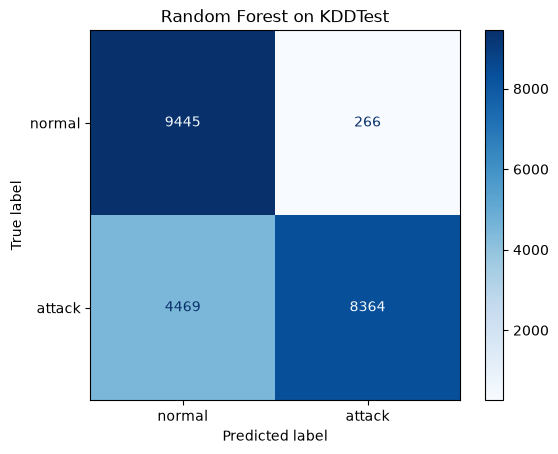

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = rf_model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["normal", "attack"]))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["normal", "attack"]).plot(cmap="Blues")
plt.title("Random Forest on KDDTest")
plt.show()

precision    recall  f1-score   support

      normal       0.68      0.97      0.80      9711
      attack       0.97      0.65      0.78     12833

    accuracy                           0.79     22544
   macro avg       0.82      0.81      0.79     22544
weighted avg       0.84      0.79      0.79     22544

In [32]:
results = pd.DataFrame({
    "class": test["class"].astype(str).values,
    "pred": y_pred
})
attacks = results[results["class"] != "normal"]

summary = attacks.groupby("class")["pred"].agg(total="count", caught="sum")
summary["recall"] = (summary["caught"] / summary["total"]).round(2)
summary["seen_in_train"] = summary.index.isin(set(train["class"].astype(str)))

print(summary.sort_values("total", ascending=False))

                 total  caught  recall  seen_in_train
class                                                
neptune           4657    4655    1.00           True
guess_passwd      1231       0    0.00           True
mscan              996     409    0.41          False
warezmaster        944     291    0.31           True
apache2            737     499    0.68          False
satan              735     735    1.00           True
processtable       685       6    0.01          False
smurf              665     665    1.00           True
back               359     339    0.94           True
snmpguess          331       0    0.00          False
saint              319     313    0.98          False
mailbomb           293       0    0.00          False
snmpgetattack      178       0    0.00          False
portsweep          157     157    1.00           True
ipsweep            141     141    1.00           True
httptunnel         133      10    0.08          False
nmap                73      

total  caught  recall  seen_in_train
class                                                
neptune           4657    4655    1.00           True
guess_passwd      1231       0    0.00           True
mscan              996     409    0.41          False
warezmaster        944     291    0.31           True
apache2            737     499    0.68          False
satan              735     735    1.00           True
processtable       685       6    0.01          False
smurf              665     665    1.00           True
back               359     339    0.94           True
snmpguess          331       0    0.00          False
saint              319     313    0.98          False
mailbomb           293       0    0.00          False
snmpgetattack      178       0    0.00          False
portsweep          157     157    1.00           True
ipsweep            141     141    1.00           True
httptunnel         133      10    0.08          False
nmap                73      73    1.00           True
pod                 41      38    0.93           True
buffer_overflow     20       3    0.15           True
multihop            18       2    0.11           True
named               17       1    0.06          False
ps                  15       2    0.13          False
sendmail            14       0    0.00          False
xterm               13       3    0.23          False
rootkit             13       0    0.00           True
teardrop            12      12    1.00           True
xlock                9       0    0.00          False
land                 7       3    0.43           True
xsnoop               4       1    0.25          False
ftp_write            3       1    0.33           True
phf                  2       1    0.50           True
loadmodule           2       0    0.00           True
perl                 2       1    0.50           True
udpstorm             2       2    1.00          False
sqlattack            2       1    0.50          False
worm                 2       0    0.00          False
imap                 1       0    0.00           True

In [1]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

def score(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return{
        "model": name,
        "accuracy": round(accuracy_score(y_true, y_pred), 3),
        "attack_precision": round(precision_score(y_true, y_pred), 3),
        "attack_recall": round(recall_score(y_true, y_pred), 3),
        "attacl_f1": round(f1_score(y_true, y_pred), 3),
        "missed_attacks": fn,
        "false_alarms": fp,
    }


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
)
from xgboost import XGBClassifier

print("All good")


All good


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier

print("All good")

All good


In [23]:
train = pd.read_parquet("../data/KDDTrain.parquet")
test  = pd.read_parquet("../data/KDDTest.parquet")

y_train = (train["class"] != "normal").astype(int)
y_test  = (test["class"]  != "normal").astype(int)

X_train = train.drop(columns=["class", "classnum"])
X_test  = test.drop(columns=["class", "classnum"])

print(X_train.shape, X_test.shape)

(125973, 36) (22544, 36)


In [4]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "XGBoost": XGBClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

results = []
fitted = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    results.append(score(name, y_test, pipe.predict(X_test)))

comparison = pd.DataFrame(results)
comparison

NameError: name 'preprocessor' is not defined

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier

print("imports ok")

imports ok


In [15]:
train = pd.read_parquet("../data/KDDTrain.parquet")
test  = pd.read_parquet("../data/KDDTest.parquet")

y_train = (train["class"] != "normal").astype(int)
y_test  = (test["class"]  != "normal").astype(int)

X_train = train.drop(columns=["class", "classnum"])
X_test  = test.drop(columns=["class", "classnum"])

cat_cols = ["protocol_type", "service", "flag"]
num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

print(X_train.shape, X_test.shape)
print(len(cat_cols), "categorical,", len(num_cols), "numeric")

(125973, 36) (22544, 36)
3 categorical, 33 numeric


In [16]:
def score(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "model": name,
        "accuracy": round(accuracy_score(y_true, y_pred), 3),
        "attack_precision": round(precision_score(y_true, y_pred), 3),
        "attack_recall": round(recall_score(y_true, y_pred), 3),
        "attack_f1": round(f1_score(y_true, y_pred), 3),
        "missed_attacks": fn,
        "false_alarms": fp,
    }

models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "XGBoost": XGBClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

results = []
fitted = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    results.append(score(name, y_test, pipe.predict(X_test)))

comparison = pd.DataFrame(results)
comparison

,model,accuracy,attack_precision,attack_recall,attack_f1,missed_attacks,false_alarms
0,Random Forest,0.790,0.969,0.652,0.779,4469,266
1,Logistic Regression,0.752,0.916,0.621,0.740,4863,734
2,XGBoost,0.794,0.968,0.660,0.785,4368,282


In [18]:
seen = set(train["class"].astype(str))
test_cls = test["class"].astype(str).values
is_attack = (test_cls != "normal")
is_seen = pd.Series(test_cls).isin(seen).values

rows = []
for name, pipe in fitted.items():
    caught = (pipe.predict(X_test) == 1)
    rows.append({
        "model": name,
        "recall_seen_attacks": round(caught[is_attack & is_seen].mean(), 3),
        "recall_unseen_attack": round(caught[is_attack & ~is_seen].mean(),3),
    })
pd.DataFrame(rows)

,model,recall_seen_attacks,recall_unseen_attack
0,Random Forest,0.784,0.333
1,Logistic Regression,0.714,0.396
2,XGBoost,0.774,0.384


In [22]:
proba = fitted["Random Forest"].predict_proba(X_test)[:,1]

tuning = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05]:
    tuning.append(score(f"RF @ {t}", y_test, (proba >= t).astype(int)))

pd.DataFrame(tuning)[["model", "attack_recall", "attack_precision", "missed_attacks", "false_alarms"]]

,model,attack_recall,attack_precision,missed_attacks,false_alarms
0,RF @ 0.5,0.655,0.969,4421,266
1,RF @ 0.4,0.684,0.970,4061,274
2,RF @ 0.3,0.724,0.938,3541,617
3,RF @ 0.2,0.805,0.924,2498,856
4,RF @ 0.1,0.887,0.923,1452,948
5,RF @ 0.05,0.924,0.920,969,1037


Random Forest, XGBoost and Logistic Regression perform within a few points of each other (attack recall 0.62 to 0.66). All three miss most attack types that never appear in training (unseen recall 0.33 to 0.40). Lowering Random Forest’s decision cutoff from 0.5 to 0.1 raised attack recall from 0.65 to 0.89 and cut missed attacks from about 4,400 to 1,450, at the cost of false alarms rising from 266 to 948.

In [23]:
rows = []
for name in ["Random Forest", "XGBoost"]:
    p = fitted[name].predict_proba(X_test)[:,1]
    for t in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05]:
        caught = (p >= t)
        rows.append({
            "model": name, "threshold":t,
            "recall_seen": round(caught[is_attack & is_seen].mean(), 3),
            "recall_unseen": round(caught[is_attack & ~is_seen].mean(), 3),
        })
pd.DataFrame(rows)

,model,threshold,recall_seen,recall_unseen
0,Random Forest,0.50,0.785,0.342
1,Random Forest,0.40,0.791,0.422
2,Random Forest,0.30,0.801,0.537
3,Random Forest,0.20,0.839,0.725
4,Random Forest,0.10,0.896,0.864
5,Random Forest,0.05,0.934,0.901
6,XGBoost,0.50,0.774,0.384
7,XGBoost,0.40,0.775,0.388
8,XGBoost,0.30,0.775,0.414
9,XGBoost,0.20,0.777,0.436


In [1]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

In [6]:
needed = ["train", "test", "X_train", "X_test", "y_train", "y_test",
          "preprocessor", "score", "fitted", "is_attack", "is_seen"]
print("missing:", [n for n in needed if n not in globals()])

missing: []


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier


train = pd.read_parquet("../data/KDDTrain.parquet")
test  = pd.read_parquet("../data/KDDTest.parquet")

y_train = (train["class"] != "normal").astype(int)
y_test  = (test["class"]  != "normal").astype(int)
X_train = train.drop(columns=["class", "classnum"])
X_test  = test.drop(columns=["class", "classnum"])


cat_cols = ["protocol_type", "service", "flag"]
num_cols = [c for c in X_train.columns if c not in cat_cols]
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])


def score(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "model": name,
        "accuracy": round(accuracy_score(y_true, y_pred), 3),
        "attack_precision": round(precision_score(y_true, y_pred), 3),
        "attack_recall": round(recall_score(y_true, y_pred), 3),
        "attack_f1": round(f1_score(y_true, y_pred), 3),
        "missed_attacks": fn,
        "false_alarms": fp,
    }


models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "XGBoost": XGBClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}
results, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    results.append(score(name, y_test, pipe.predict(X_test)))


seen = set(train["class"].astype(str))
test_cls = test["class"].astype(str).values
is_attack = (test_cls != "normal")
is_seen = pd.Series(test_cls).isin(seen).values

pd.DataFrame(results)

,model,accuracy,attack_precision,attack_recall,attack_f1,missed_attacks,false_alarms
0,Random Forest,0.790,0.969,0.652,0.779,4469,266
1,Logistic Regression,0.752,0.916,0.621,0.740,4863,734
2,XGBoost,0.794,0.968,0.660,0.785,4368,282


In [7]:
proba_rf = fitted["Random Forest"].predict_proba(X_test)[:, 1]
print("Real attacks at exactly 0.5:", ((proba_rf == 0.5) & (y_test ==1)).sum())

Real attacks at exactly 0.5: 48


In [17]:
rows = []
for t in [0.5, 0.4, 0.1, 0.05]:
    caught = proba_rf >= t
    rows.append({
        "threshold": t,
        "recall_seen": round(caught[is_attack & is_seen].mean(), 3),
        "recall_unseen": round(caught[is_attack & ~is_seen].mean(), 3),
    })
pd.DataFrame(rows)

,threshold,recall_seen,recall_unseen
0,0.50,0.785,0.342
1,0.40,0.791,0.422
2,0.10,0.896,0.864
3,0.05,0.934,0.901


In [19]:
tp = pd.DataFrame({"cls": test_cls[is_attack & ~is_seen], "p": proba_rf[is_attack & ~is_seen]})
tp["caught_0.5"] = tp["p"] >= 0.5
tp["caught_0.1"] = tp["p"] >= 0.1
tp.groupby("cls")[["caught_0.5", "caught_0.1"]].agg({"mean"}).round(2)

,caught_0.5,caught_0.1
,mean,mean
cls,,
apache2,0.70,1.00
httptunnel,0.08,0.90
mailbomb,0.00,0.04
mscan,0.43,1.00
named,0.06,0.76
processtable,0.01,1.00
ps,0.13,0.73
saint,0.98,1.00
